In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
print("libraries imported successfully")
print("current working directory:",os.getcwd())

libraries imported successfully
current working directory: C:\Users\banda


In [3]:
file_path="Online Retail.xlsx"
df=pd.read_excel(file_path)

print("Data loaded successfully")
print("no.of rows and columns:",df.shape)

print(df.head())

Data loaded successfully
no.of rows and columns: (541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


Inspection of Data

In [4]:
print("shape of dataset:",df.shape)

shape of dataset: (541909, 8)


In [5]:
print("columns names:",df.columns.to_list())

columns names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [6]:
print("non-null values,dtypes:",df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
non-null values,dtypes: None


In [7]:
print("null values:",df.isnull().sum())

null values: InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [8]:
print("numerical summary:",df.describe())

numerical summary:             Quantity      UnitPrice     CustomerID
count  541909.000000  541909.000000  406829.000000
mean        9.552250       4.611114   15287.690570
std       218.081158      96.759853    1713.600303
min    -80995.000000  -11062.060000   12346.000000
25%         1.000000       1.250000   13953.000000
50%         3.000000       2.080000   15152.000000
75%        10.000000       4.130000   16791.000000
max     80995.000000   38970.000000   18287.000000


Data-Quality

In [9]:
#duplicates rows
print("Duplicated rows:",df.duplicated().sum())

Duplicated rows: 5268


In [10]:
#check missing values and percentages
missing =pd.DataFrame({"missing_count":df.isnull().sum(),"missing_percentage":(df.isnull().sum() / len(df)*100).round(2)})
print(missing)

             missing_count  missing_percentage
InvoiceNo                0                0.00
StockCode                0                0.00
Description           1454                0.27
Quantity                 0                0.00
InvoiceDate              0                0.00
UnitPrice                0                0.00
CustomerID          135080               24.93
Country                  0                0.00


In [11]:
#check negative nad zero quantities
print("negative quantity rows:",(df["Quantity"]<0).sum())
print("zero quantity rows:",(df["Quantity"]==0).sum())


negative quantity rows: 10624
zero quantity rows: 0


In [12]:
#check negative,zero and positive unit prices
print("negative unit prices:",(df["UnitPrice"]<0).sum())
print("zero unit prices:",(df["UnitPrice"]==0).sum())
print("positive unit prices:",(df["UnitPrice"]>0).sum())

negative unit prices: 2
zero unit prices: 2515
positive unit prices: 539392


In [13]:
#Identify cancellation invoices
cancelled=df["InvoiceNo"].astype(str).str.startswith("C")
print("camcellation invoice rows:",cancelled.sum())

camcellation invoice rows: 9288


In [14]:
#check the date range
print("earliest transaction:",df["InvoiceDate"].min())
print("latest transaction:",df["InvoiceDate"].max())

earliest transaction: 2010-12-01 08:26:00
latest transaction: 2011-12-09 12:50:00


Data cleaning

In [15]:
#create a sepearate working copy
df_clean=df.copy()

In [16]:
#shape of data
print("original data shape:",df.shape)
print("clean data shape:",df_clean.shape)

original data shape: (541909, 8)
clean data shape: (541909, 8)


In [17]:
#duplicate rows
duplicate_count=df_clean.duplicated().sum()
print("Exact duplicate rows:",duplicate_count)

Exact duplicate rows: 5268


In [18]:
#remove duplicates
df_clean=df_clean.drop_duplicates().copy()
print("cleaned data shape:",df_clean.shape)
print("remaining duplicates:",df_clean.duplicated().sum())

cleaned data shape: (536641, 8)
remaining duplicates: 0


Handling Missing values after removing duplicates

In [19]:
print("Missing values in each column:")
print(df_clean.isnull().sum())

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [20]:
print("missing value percentag:")
print((df_clean.isnull().sum()/len(df_clean)*100).round(2))

missing value percentag:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     25.16
Country         0.00
dtype: float64


clean extra spaces in description

In [21]:
df_clean["Description"]=df_clean["Description"].str.strip()


In [22]:
#check missing desciption and customer id
print("Missing description:",df_clean["Description"].isnull().sum())
print("Missing customer_id:",df_clean["CustomerID"].isnull().sum())

Missing description: 1455
Missing customer_id: 135037


Investigate cancellations,returns,unusual prices

In [23]:
df_clean["Description"]=df_clean["Description"].replace(r"^\s*S",np.nan,regex=True)

In [24]:
#identify cancellations
df_clean["InvoiceNo"]=df_clean["InvoiceNo"].astype(str)
cancellation_mask=df_clean["InvoiceNo"].str.startswith("C")

In [25]:
print("cancellation invoice rows:",cancellation_mask.sum())

cancellation invoice rows: 9251


In [26]:
#investigate quantities
print("negative quantity rows:",(df_clean["Quantity"]<0).sum())
print("zero quantity rows:",(df_clean["Quantity"]==0).sum())
print("positive quantity rows:",(df_clean["Quantity"]>0).sum())

negative quantity rows: 10587
zero quantity rows: 0
positive quantity rows: 526054


In [27]:
#investigate unitprices
print("negative unit prices:",(df_clean["UnitPrice"]<0).sum())
print("zero unit prices:",(df_clean["UnitPrice"]==0).sum())
print("positive unit prices:",(df_clean["UnitPrice"]>0).sum())

negative unit prices: 2
zero unit prices: 2510
positive unit prices: 534129


In [28]:
#Example of cancellation records
print("example cancellation records:")
print(df_clean.loc[cancellation_mask].head())

example cancellation records:
    InvoiceNo StockCode                      Description  Quantity  \
141   C536379         D                         Discount        -1   
154   C536383    35004C                              NaN        -1   
235   C536391     22556    PLASTERS IN TIN CIRCUS PARADE       -12   
236   C536391     21984  PACK OF 12 PINK PAISLEY TISSUES       -24   
237   C536391     21983  PACK OF 12 BLUE PAISLEY TISSUES       -24   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00      27.50     14527.0  United Kingdom  
154 2010-12-01 09:49:00       4.65     15311.0  United Kingdom  
235 2010-12-01 10:24:00       1.65     17548.0  United Kingdom  
236 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  
237 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  


In [29]:
#Inspect negative quntity
print("neagtive quantity records:")
print(df_clean.loc[df_clean["Quantity"]<0].head())

neagtive quantity records:
    InvoiceNo StockCode                      Description  Quantity  \
141   C536379         D                         Discount        -1   
154   C536383    35004C                              NaN        -1   
235   C536391     22556    PLASTERS IN TIN CIRCUS PARADE       -12   
236   C536391     21984  PACK OF 12 PINK PAISLEY TISSUES       -24   
237   C536391     21983  PACK OF 12 BLUE PAISLEY TISSUES       -24   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00      27.50     14527.0  United Kingdom  
154 2010-12-01 09:49:00       4.65     15311.0  United Kingdom  
235 2010-12-01 10:24:00       1.65     17548.0  United Kingdom  
236 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  
237 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  


In [30]:
#Inspect negative unnitprice
print("neagtive unitprice records:")
print(df_clean.loc[df_clean["UnitPrice"]<0].head())

neagtive unitprice records:
       InvoiceNo StockCode      Description  Quantity         InvoiceDate  \
299983   A563186         B  Adjust bad debt         1 2011-08-12 14:51:00   
299984   A563187         B  Adjust bad debt         1 2011-08-12 14:52:00   

        UnitPrice  CustomerID         Country  
299983  -11062.06         NaN  United Kingdom  
299984  -11062.06         NaN  United Kingdom  


create a separate dataset for positive_sales analysis

In [31]:
cancellation_mask=df_clean["InvoiceNo"].str.startswith("C")

sales_df=df_clean.loc[(~cancellation_mask)&(df_clean["Quantity"]>0)&(df_clean["UnitPrice"]>0)].copy()

In [32]:
#calculate sales values
sales_df["Revenue"]=sales_df["Quantity"]*sales_df["UnitPrice"]

print("original rows:",sales_df.shape)
print("Original dataset rows:", len(df))
print("Rows after duplicate removal:",len(df_clean))
print("positive-sales rows:",len(sales_df))
print("positive-sales value:",round(sales_df["Revenue"].sum(),2))
print("remaining  non positive quantities:",(sales_df["Quantity"]<=0).sum())
print("reamining non positive prices:",(sales_df["UnitPrice"]<=0).sum())

original rows: (524878, 9)
Original dataset rows: 541909
Rows after duplicate removal: 536641
positive-sales rows: 524878
positive-sales value: 10642110.8
remaining  non positive quantities: 0
reamining non positive prices: 0


In [33]:
print(sales_df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  


Calculate business KPIs

In [34]:
Total_Revenue=sales_df["Revenue"].sum()
Total_orders=sales_df["InvoiceNo"].nunique()
Total_units_sold=sales_df["Quantity"].sum()
average_order_value=Total_Revenue/Total_orders

In [35]:
Identified_customers=sales_df["CustomerID"].nunique()
unique_products=sales_df["StockCode"].nunique()
unique_countries=sales_df["Country"].nunique()

In [36]:
print("Business KPI Summary:")
print("positive_sales value:",round(Total_Revenue,2))
print("number of orders:",Total_orders)
print("Total units sold:",Total_units_sold)
print("average_order_value:",round(average_order_value),2)
print("Identified_customers:",Identified_customers)
print("unique_products:",unique_products)
print("unique_countries:",unique_countries)

Business KPI Summary:
positive_sales value: 10642110.8
number of orders: 19960
Total units sold: 5572420
average_order_value: 533 2
Identified_customers: 4338
unique_products: 3922
unique_countries: 38


Monthly sales trend analysis

In [37]:
#monthly sales
sales_df["YearMonth"]=sales_df["InvoiceDate"].dt.to_period("M")

monthly_sales=(sales_df.groupby("YearMonth")["Revenue"].sum().reset_index())
monthly_sales["YearMonth"]=monthly_sales["YearMonth"].astype(str)
print("monthly sales summary:")
display(monthly_sales)

monthly sales summary:


,YearMonth,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


plot monthly sales trend

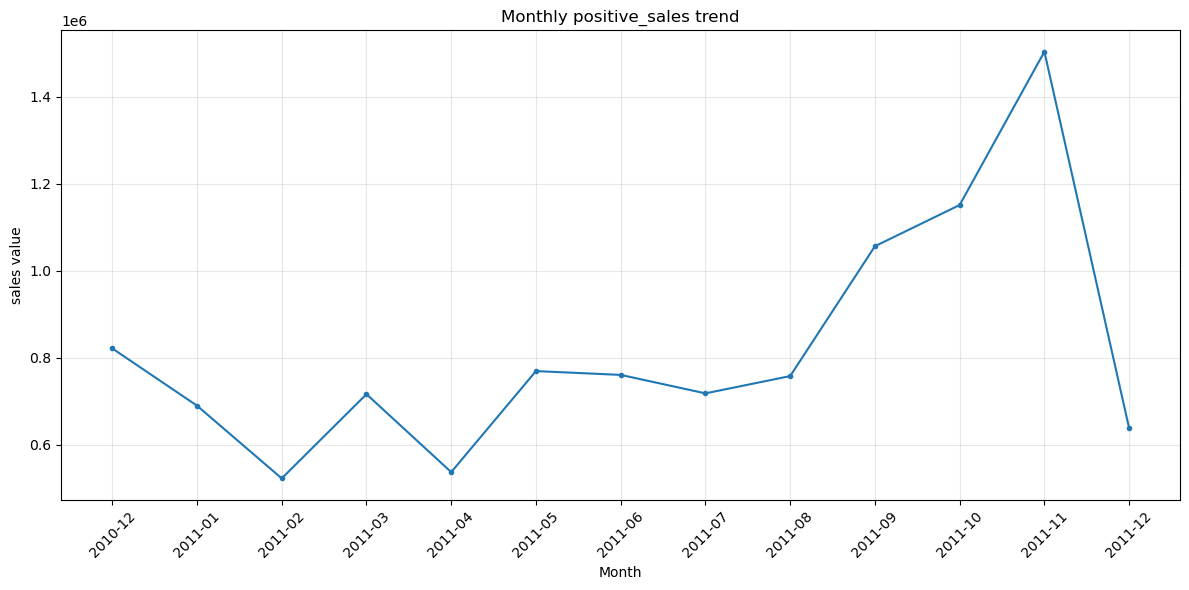

In [38]:
plt.figure(figsize=(12,6))
plt.plot(monthly_sales["YearMonth"],monthly_sales["Revenue"],marker=".")
plt.title("Monthly positive_sales trend")
plt.xlabel("Month")
plt.ylabel("sales value")
plt.xticks(rotation=45)
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

Find the top 10 products by sales value

In [39]:
top_products=(sales_df.groupby(["StockCode","Description"])["Revenue"].sum().sort_values(ascending=False).head(10).reset_index())

top_products["Revenue"]=top_products["Revenue"].round(2)
print("top 10 products by sales value:")
print(top_products)

top 10 products by sales value:
  StockCode                         Description    Revenue
0       DOT                      DOTCOM POSTAGE  206248.77
1     22423            REGENCY CAKESTAND 3 TIER  174156.54
2     23843         PAPER CRAFT , LITTLE BIRDIE  168469.60
3    85123A  WHITE HANGING HEART T-LIGHT HOLDER  104284.24
4     47566                       PARTY BUNTING   99445.23
5    85099B             JUMBO BAG RED RETROSPOT   94159.81
6     23166      MEDIUM CERAMIC TOP STORAGE JAR   81700.92
7      POST                             POSTAGE   78101.88
8         M                              Manual   77750.27
9     23084                  RABBIT NIGHT LIGHT   66870.03


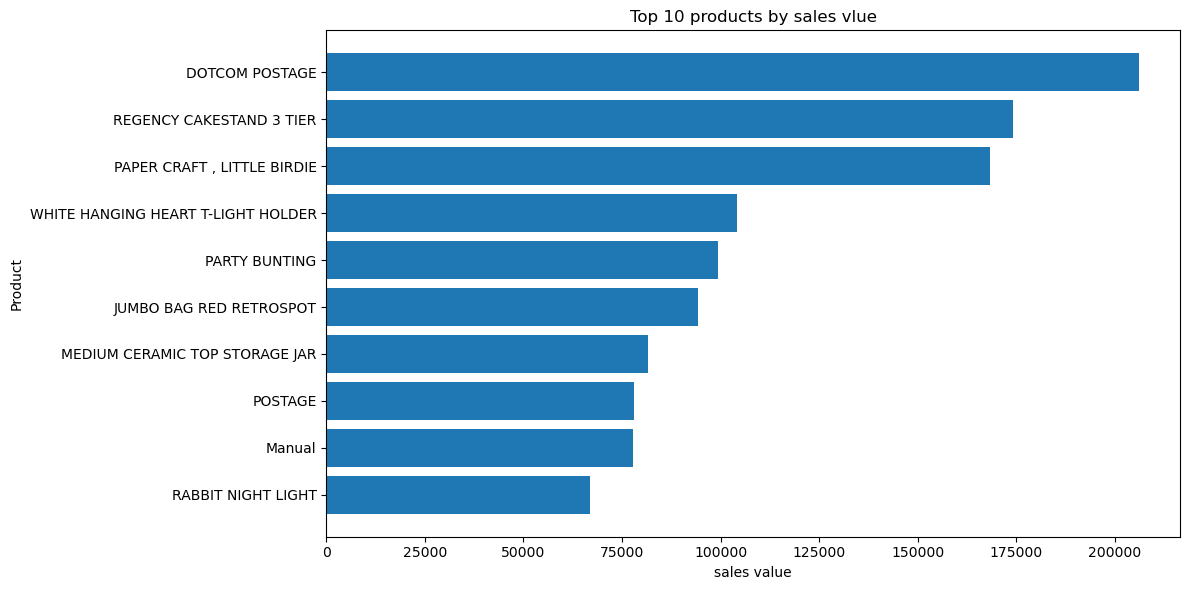

In [40]:
plt.figure(figsize=(12,6))
plt.barh( 
        top_products["Description"].astype(str).str.slice(0,35)[::-1],
        top_products["Revenue"][::-1])
plt.title("Top 10 products by sales vlue")
plt.xlabel("sales value")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [41]:
#top 10 countries
country_sales=(sales_df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10).reset_index())
country_sales["Revenue"]=country_sales["Revenue"].round(2)
print("Top 10 countries by sales value:")
print(country_sales)

Top 10 countries by sales value:
          Country     Revenue
0  United Kingdom  9001744.09
1     Netherlands   285446.34
2            EIRE   283140.52
3         Germany   228678.40
4          France   209625.37
5       Australia   138453.81
6           Spain    61558.56
7     Switzerland    57067.60
8         Belgium    41196.34
9          Sweden    38367.83


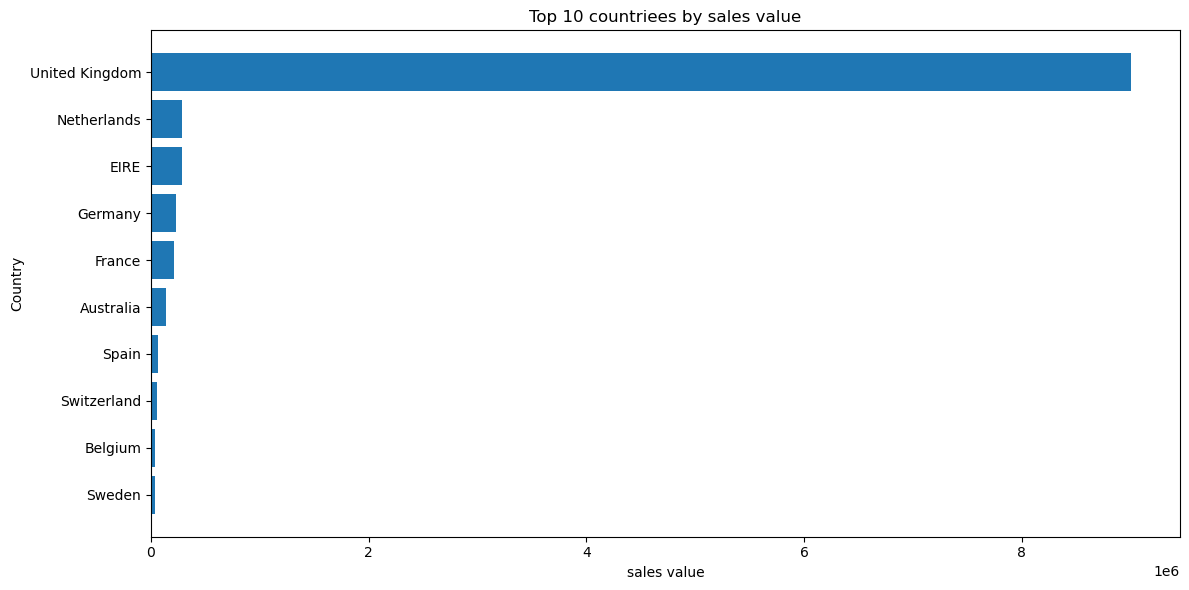

In [42]:
#visualize sales by country
plt.figure(figsize=(12,6))
plt.barh(country_sales["Country"][::-1],country_sales["Revenue"][::-1])
plt.title("Top 10 countriees by sales value")
plt.xlabel("sales value")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [43]:
#customer analysis
customer_df=sales_df.dropna(subset=["CustomerID"]).copy()

customer_summary=(customer_df.groupby("CustomerID").agg(Revenue=("Revenue","sum"),Orders=("InvoiceNo","nunique"),Units=("Quantity","sum")).reset_index())

print("Number of identifiable customers:",customer_summary["CustomerID"].nunique())
print("Number of repeat customers:",(customer_summary["Orders"]>1).sum())
print("Average sales value per customer:",round(customer_summary["Revenue"].mean(),2))                                                      

Number of identifiable customers: 4338
Number of repeat customers: 2845
Average sales value per customer: 2048.69


In [44]:
#Top 10 customers by sales value
top_customers=(customer_summary.sort_values("Revenue",ascending=False).head(10).copy())
top_customers["Revenue"]=top_customers["Revenue"].round(2)

print("Top customers by slaes value:")
print(top_customers)

Top customers by slaes value:
      CustomerID    Revenue  Orders   Units
1689     14646.0  280206.02      73  196915
4201     18102.0  259657.30      60   64124
3728     17450.0  194390.79      46   69973
3008     16446.0  168472.50       2   80997
1879     14911.0  143711.17     201   80240
55       12415.0  124914.53      21   77374
1333     14156.0  117210.08      55   57768
3771     17511.0   91062.38      31   64549
2702     16029.0   80850.84      63   40108
0        12346.0   77183.60       1   74215


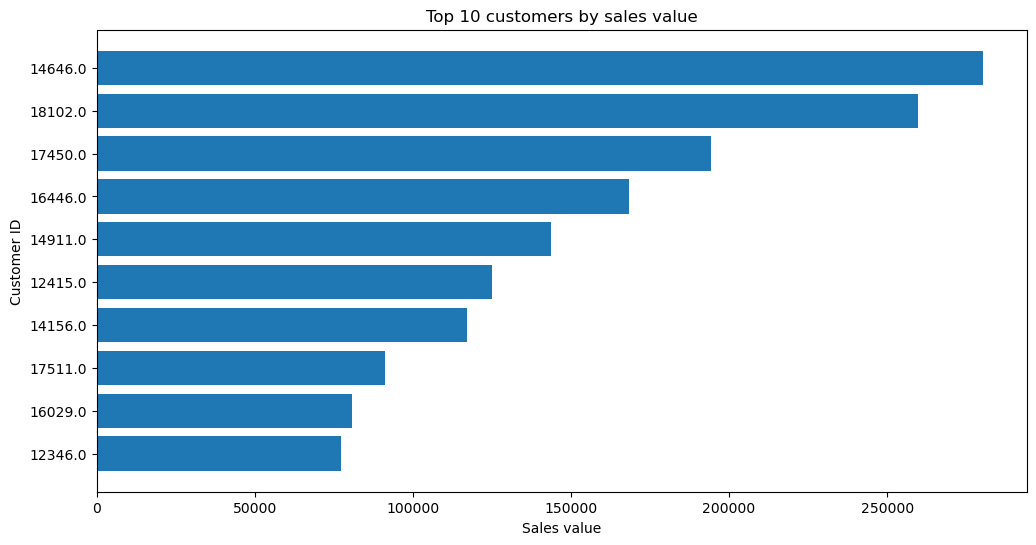

In [45]:
#top 10 customers and their sales value
plt.figure(figsize=(12,6))
plt.barh(top_customers["CustomerID"].astype(str)[::-1],top_customers["Revenue"][::-1])
plt.title("Top 10 customers by sales value")
plt.xlabel("Sales value")
plt.ylabel("Customer ID")
plt.show()

In [46]:
#Final businness metrics
repeat_customers=(customer_summary["Orders"]>1).sum()
total_customers=customer_summary["CustomerID"].nunique()

repeat_customers_percentage=(repeat_customers/total_customers)*100

print("FINAL BUSINESS SUMMARY")
print("_" * 35)
print(f"positive_sales value:{sales_df['Revenue'].sum():,.2f}")
print(f"total orders:{sales_df['InvoiceNo'].nunique():,}")
print(f"Total units sold:{sales_df['Quantity'].sum():,}")
print(f"Identifiable customers:{total_customers:,}")
print(f"Repeat customers:{repeat_customers:,}")
print(f"repeat_customers_percentage:{repeat_customers_percentage:,.2f}")
print(f"Unique products:{sales_df['StockCode'].nunique():,}")
print(f"countries served:{sales_df['Country'].nunique():,}")

FINAL BUSINESS SUMMARY
___________________________________
positive_sales value:10,642,110.80
total orders:19,960
Total units sold:5,572,420
Identifiable customers:4,338
Repeat customers:2,845
repeat_customers_percentage:65.58
Unique products:3,922
countries served:38


# Key Findings and Conclusion

## Key Findings

1. **Overall sales:** The dataset contains a positive-sales value of 10,642,110.80 across 19,960 distinct invoices.
2. **Monthly performance:** November 2011 recorded the highest monthly positive-sales value, at approximately 1,503,866.78.
3. **Product performance:** DOTCOM POSTAGE generated the highest sales value among the top 10 products, at 206,248.77.
4. **Country performance:** The United Kingdom was the largest market, contributing 9,001,744.09 in positive-sales value.
5. **Customer behavior:** The dataset contains 4,338 identifiable customers, of whom 2,845 (65.58%) placed more than one order.
6. **Product variety:** The business sold 3,922 distinct stock codes across 38 countries.

## Business Recommendations

- Investigate the reasons for the strong sales performance in November.
- Explore opportunities to grow sales in countries outside the United Kingdom.
- Encourage repeat purchases through customer retention campaigns.
- Monitor top-performing products and maintain appropriate inventory levels.
- Analyze cancellations and returns separately to understand their impact on net sales.

## Conclusion

This project analyzed an online retail dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn. The analysis covered data cleaning, business KPI calculations, monthly sales trends, product performance, country-level sales, and customer purchasing behavior.

The findings demonstrate how data analysis can help businesses identify important markets, understand customer behavior, and make more informed decisions.

## Limitations

- The analysis covers the period December 2010 to December 2011.
- Positive-sales value is calculated from positive quantities and positive unit prices; it is not profit or net revenue after returns.
- Customer-level analysis excludes transactions without an identifiable CustomerID.
- Sales value alone does not measure profitability because product costs and other expenses are not provided.